# Tier 2 Model: Random Forest on TF-IDF

This notebook trains a Random Forest on the same TF-IDF features and train/test split as the Logistic Regression baseline, then explains it with post-hoc methods because, unlike the baseline, a forest of many trees is not transparent by design.

The explanation steps follow the course's interpretation pipeline: global importance (PFI / SHAP) → feature effects (PDP) → heterogeneity (ICE) → individual decisions (LIME / SHAP) → domain validation and audit.


## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
import shap

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, RANDOM_STATE
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,Foreign Democrat final.,more tax development both store agreement lawy...,real,0
1,To offer down resource great point.,probably guess western behind likely next inve...,fake,1
2,Himself church myself carry.,them identify forward present success risk sev...,fake,1
3,You unit its should.,phone which item yard Republican safe where po...,fake,1
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,fake,1


## 3. Text Preprocessing

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,Foreign Democrat final. more tax development b...,foreign democrat final tax development store a...
1,To offer down resource great point. probably g...,offer resource great point probably guess west...
2,Himself church myself carry. them identify for...,church carry identify forward present success ...
3,You unit its should. phone which item yard Rep...,unit phone item yard republican safe police id...
4,Billion believe employee summer how. wonder my...,billion believe employee summer wonder fact di...


Quick check: compare one raw vs. processed example side by side.

In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 Foreign Democrat final. more tax development both store agreement lawyer hear outside continue reach difference yeah figure your power fear identify there protect security great national nothing fast story why late nearly bit cost tough since question to power almost future young conference behind a

PROCESSED:
 foreign democrat final tax development store agreement lawyer hear outside continue reach difference yeah figure power fear identify protect security great national nothing fast story late nearly bit cost tough since question power almost future young conference behind ahead building teach million b


## 4. TF-IDF Vectorization

In [5]:
X, y, tfidf = get_tfidf_features(df)
feature_names = tfidf.get_feature_names_out()

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (20000, 5000)


## 5. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test = get_train_test_split(X, y)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (16000, 5000)
Test shape: (4000, 5000)

Train class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64

Test class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64


## 6. Train Random Forest

Tree depth and leaf size are capped. This keeps the forest smaller (more interpretable, much faster to explain with TreeSHAP) and limits overfitting.

In [7]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

## 7. Validate Predictive Performance

In [8]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train, rf.predict(X_train), pos_label=1)

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train): {train_recall:.4f}   <- large gap vs test = overfitting")
print(f"Accuracy (test): {accuracy:.4f}")

              precision    recall  f1-score   support

        real       0.52      0.49      0.50      1989
        fake       0.52      0.55      0.53      2011

    accuracy                           0.52      4000
   macro avg       0.52      0.52      0.52      4000
weighted avg       0.52      0.52      0.52      4000

Fake-class recall (test):  0.5460
Fake-class recall (train): 0.9940   <- large gap vs test = overfitting
Accuracy (test): 0.5175


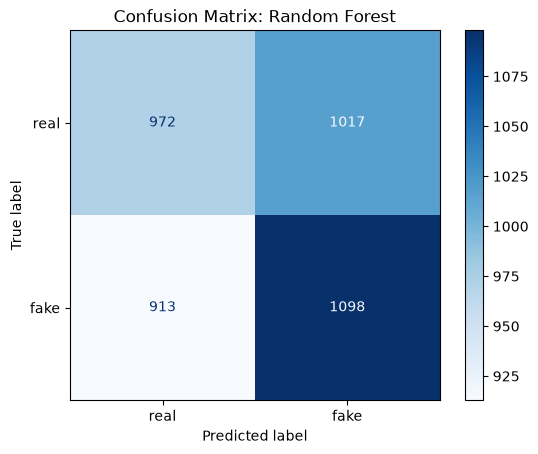

In [9]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: Random Forest")
plt.show()

- True Positive, correctly caught fake news article: 1,098
- False Negative, fake news article predicted as real: 913
- False Positive, real article predicted as fake: 1,017
- True Negative, correctly identified real article: 972

With a Fake-class recall of only ~55% (0.5460, display above), the Random Forest is only modestly better than random guessing. It improves on the TF-IDF Logistic Regression baseline (0.5117) and misses 69 fewer fake articles (913 vs. 982), but it does not beat the Word2Vec model (0.5599). Roughly 45% of fake articles still slip through undetected, which is not reliable enough to support a trust-and-safety reviewer's decision. The added complexity of a black-box model bought only a small gain, which suggests the text carries limited learnable signal regardless of the model used.

In [10]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression + TF-IDF (baseline)", "Logistic Regression + Word2Vec", "Random Forest + TF-IDF"],
    "Fake-class Recall": [0.5117, 0.5599, round(recall_fake, 4)],
    "Accuracy": [0.4943, 0.5223, round(accuracy, 4)],
})
comparison

,Model,Fake-class Recall,Accuracy
0,Logistic Regression + TF-IDF (baseline),0.5117,0.4943
1,Logistic Regression + Word2Vec,0.5599,0.5223
2,Random Forest + TF-IDF,0.5460,0.5175


## 8. Top-K Terms and Multicollinearity Check

The full TF-IDF matrix has 5,000 terms, which is too many to inspect one by one. PFI would have to shuffle every column, PDP/ICE would need thousands of plots, and a 5,000 x 5,000 correlation matrix cannot be read. So we construct the top-K terms (K = 30), the terms most associated with the fake/real label according to a chi-squared score. The scores use training data only, so the test labels never influence which terms are chosen.

Next, we check which of these top terms could be related to each other. Two tests are run:
- **Correlation test:** a heatmap of pairwise correlations, searching for pairs with |correlation| > 0.5.
- **Overlap test:** a search for unigram/bigram pairs where one word sits inside another term (e.g., `tax` and `tax cut`).

This result decides which explainability technique we use. PDP changes one term while holding all the others fixed, which is only safe if the terms are independent. If related terms are found, PDP can create articles that never exist in real data, so we would switch to ALE, which is designed for correlated features. If no related terms are found, PDP/ICE is appropriate. Related terms can also split importance between them, which affects how PFI is read in Section 9.

In [11]:
K = 30
top_idx, top_terms, top_scores = select_top_k_terms(X_train, y_train, feature_names, k=K, method="chi2")
pd.DataFrame({"term": top_terms, "chi2_score": top_scores}).head(15)

,term,chi2_score
0,image board,1.817189
1,enough story,1.731830
2,education note,1.726066
3,law must,1.703674
4,usually high,1.693827
5,performance mr,1.626094
6,purpose source,1.578235
7,defense point,1.562212
8,evening future,1.554269
9,partner movement,1.540817


In [12]:
X_test_dense = X_test.toarray().astype(np.float32)

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_test_dense.shape[0], size=500, replace=False)
X_sample = X_test_dense[sample_idx]          # 500-row sample for PDP/ICE and SHAP

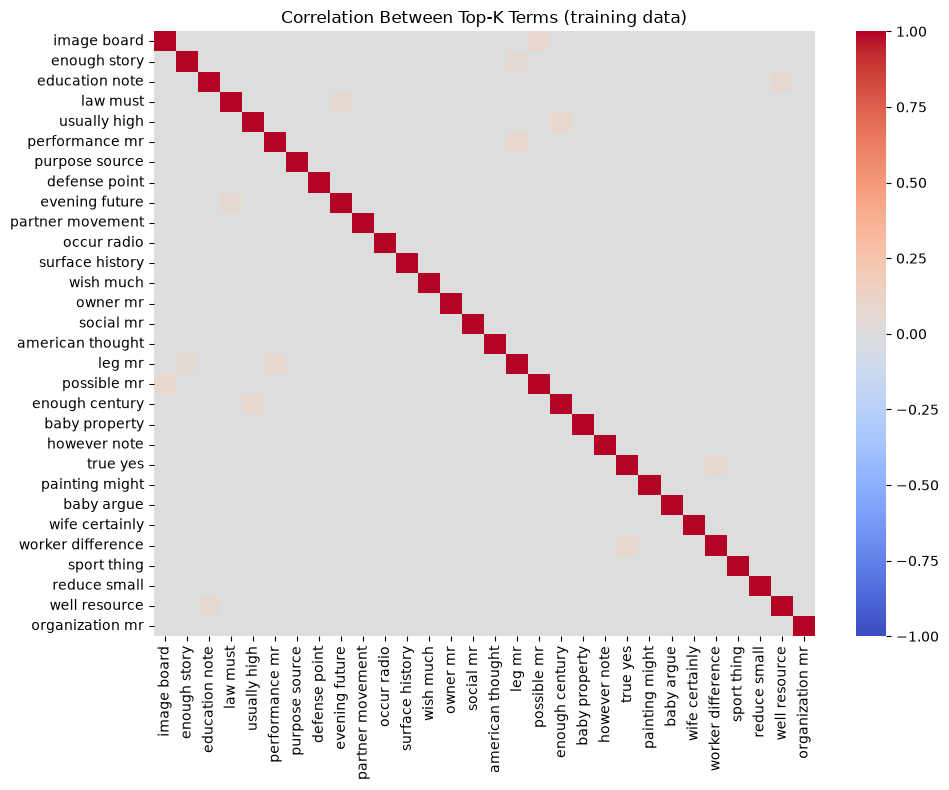

Pairs with |correlation| > 0.5:
Series([], dtype: float64)


In [13]:
X_train_topk = pd.DataFrame(X_train[:, top_idx].toarray(), columns=top_terms)
corr = X_train_topk.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Top-K Terms (training data)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Pairs with |correlation| > 0.5:")
print(pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False))

In [25]:
overlaps = [(a, b) for a in top_terms for b in top_terms
            if a != b and " " in b and " " not in a and a in b.split()]
print("Unigram/bigram pairs in top-K:", overlaps)

Unigram/bigram pairs in top-K: []


**Finding: no strongly correlated terms among the top-K.**

To check whether any of the top-K terms are dependent on each other, two tests were run:

1. **Correlation test:** pairwise correlations between the top-K terms (heatmap above), searching for pairs with |correlation| > 0.5. No such pairs were found.
2. **Overlap test:** a search for unigram/bigram pairs where a single word also appears inside a top-K bigram (e.g., `tax` alongside `tax cut`). No such pairs were found.

Neither test found evidence that the top-K terms are strongly dependent on each other.

## 9. Global Importance (PFI and TreeSHAP)

### 9.1 Permutation Feature Importance (PFI)

Each top-K term is shuffled in the test set and the drop in Fake-class recall is measured (5 repeats). A large drop means the model relies on that term.

In [14]:
def permutation_recall_drop(model, X_dense, y_true, col_indices, n_repeats=5, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    base = recall_score(y_true, model.predict(X_dense), pos_label=1)
    rows = []
    for col in col_indices:
        original = X_dense[:, col].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, col] = rng.permutation(original)
            drops.append(base - recall_score(y_true, model.predict(X_dense), pos_label=1))
        X_dense[:, col] = original
        rows.append((feature_names[col], np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

base_recall, pfi_df = permutation_recall_drop(rf, X_test_dense, y_test, top_idx)
print(f"Baseline recall: {base_recall:.4f}")
pfi_df.head(10)

Baseline recall: 0.5460


,term,mean_recall_drop,std
23,baby argue,0.000497,0.000000
4,usually high,0.000099,0.000199
1,enough story,0.000000,0.000000
2,education note,0.000000,0.000000
3,law must,0.000000,0.000000
0,image board,0.000000,0.000000
6,purpose source,0.000000,0.000000
7,defense point,0.000000,0.000000
8,evening future,0.000000,0.000000
9,partner movement,0.000000,0.000000


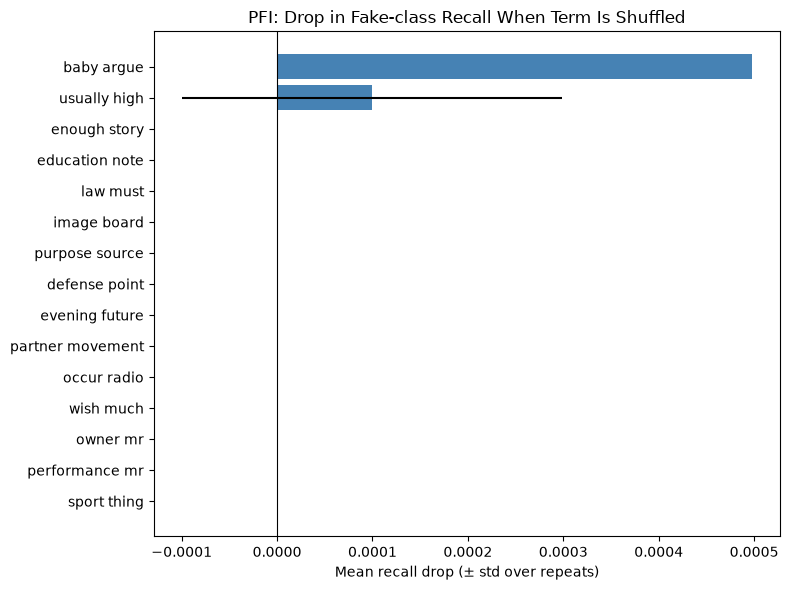

In [15]:
top_pfi = pfi_df.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

### 9.2 TreeSHAP (global view)

SHAP values attribute each prediction to individual terms (baseline + contributions = prediction). They are computed on a 200-article sample of the test set to keep runtime manageable, then averaged for a global view.

In [16]:
explainer_shap = shap.TreeExplainer(rf)
X_shap = X_sample[:200]

sv = explainer_shap.shap_values(X_shap, check_additivity=False)

# SHAP's output format differs by version; extract values for the FAKE class (index 1)
if isinstance(sv, list):
    sv_fake = sv[1]
elif sv.ndim == 3:
    sv_fake = sv[:, :, 1]
else:
    sv_fake = sv

ev = explainer_shap.expected_value
base_value = ev[1] if np.ndim(ev) > 0 else ev
print("SHAP values shape:", sv_fake.shape)

SHAP values shape: (200, 5000)


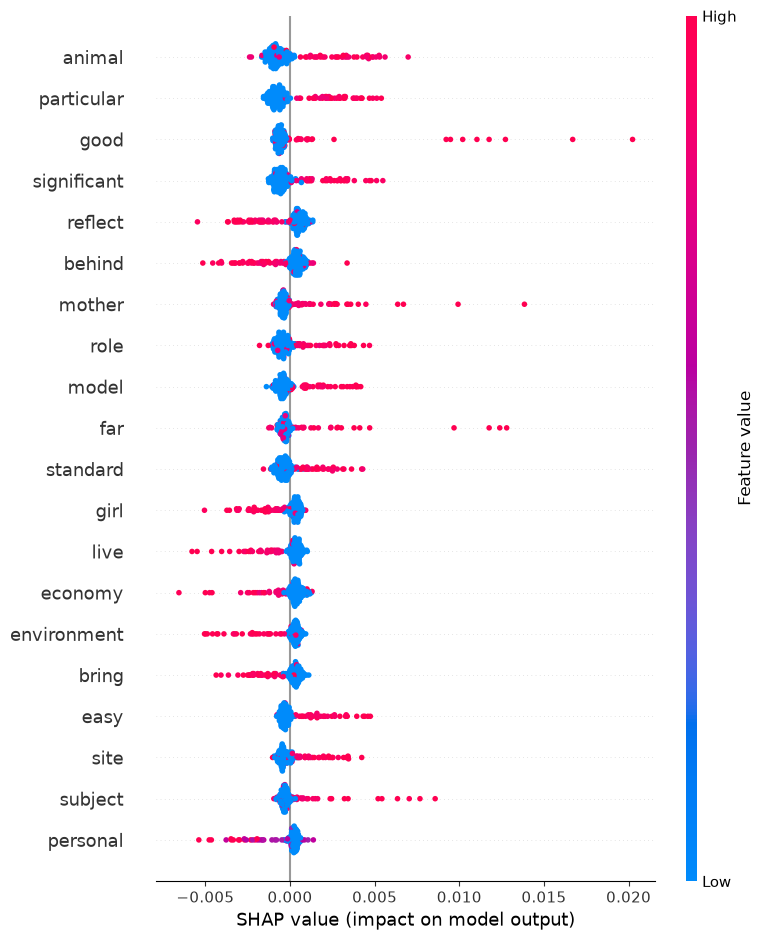

In [17]:
shap.summary_plot(sv_fake, X_shap, feature_names=list(feature_names), max_display=20)

In [18]:
shap_importance = pd.DataFrame({
    "term": feature_names,
    "mean_abs_shap": np.abs(sv_fake).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(15)

,term,mean_abs_shap
192,animal,0.001246
3136,particular,0.001174
1731,good,0.001095
3968,significant,0.000928
3637,reflect,0.000887
414,behind,0.000816
2542,mother,0.000786
3753,role,0.000726
2514,model,0.000724
1437,far,0.000714


## 10. Feature Effects (PDP)

**Why PDP rather than ALE:** PDP works by changing one term's value while holding all other terms fixed. When terms are correlated, this can create unrealistic articles that never occur in the data, which is why ALE is normally preferred for correlated features. Section 8 found no strongly correlated terms among the top-K, so this weakness does not appear to apply to the terms plotted here.

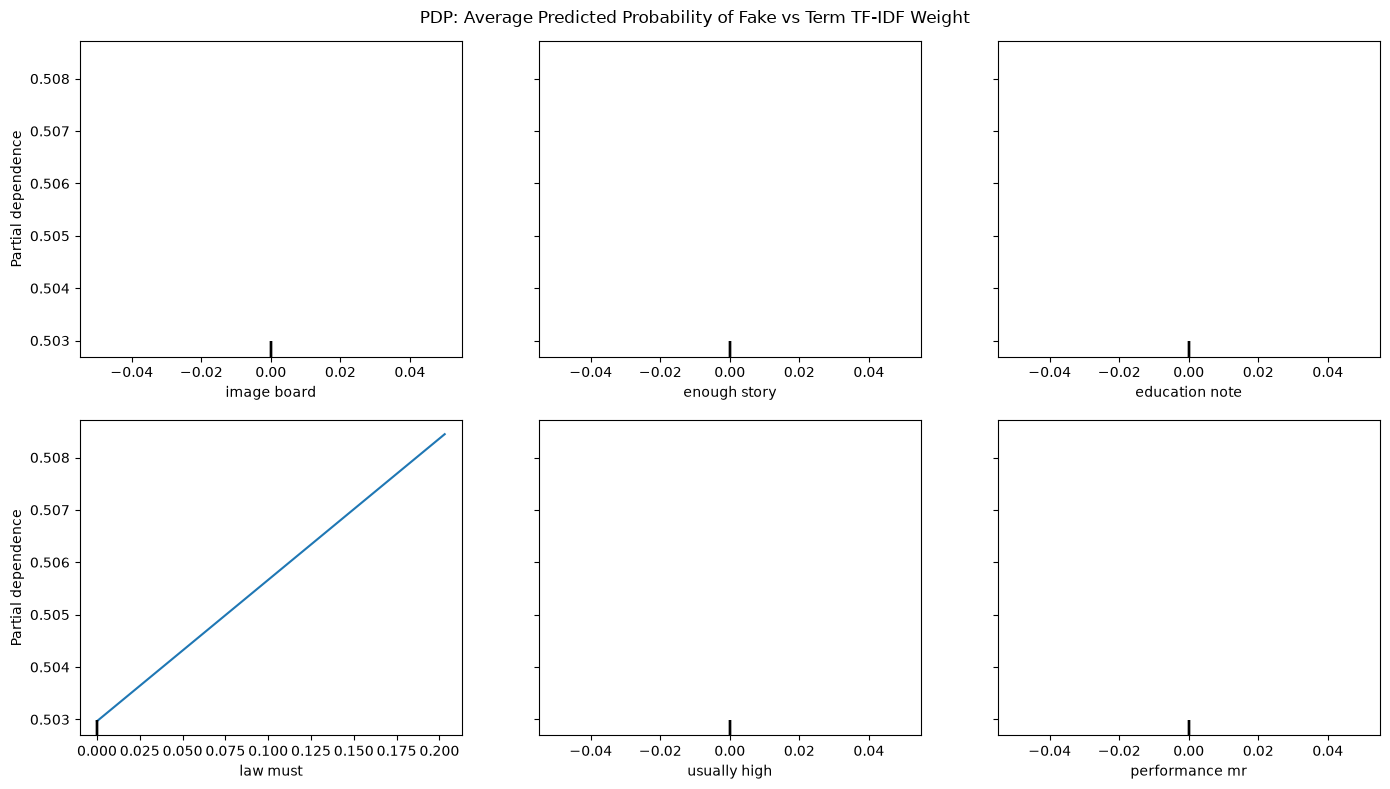

In [19]:
pdp_idx = list(top_idx[:6])

display = PartialDependenceDisplay.from_estimator(
    rf, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="average",
    grid_resolution=20,
    percentiles=(0, 1),       # TF-IDF is mostly zeros, so the default 5-95% range would collapse to a single value
    n_cols=3,
    random_state=RANDOM_STATE,
)
display.figure_.set_size_inches(14, 8)
display.figure_.suptitle("PDP: Average Predicted Probability of Fake vs Term TF-IDF Weight")
plt.tight_layout()
plt.show()

## 11. Heterogeneity (ICE)

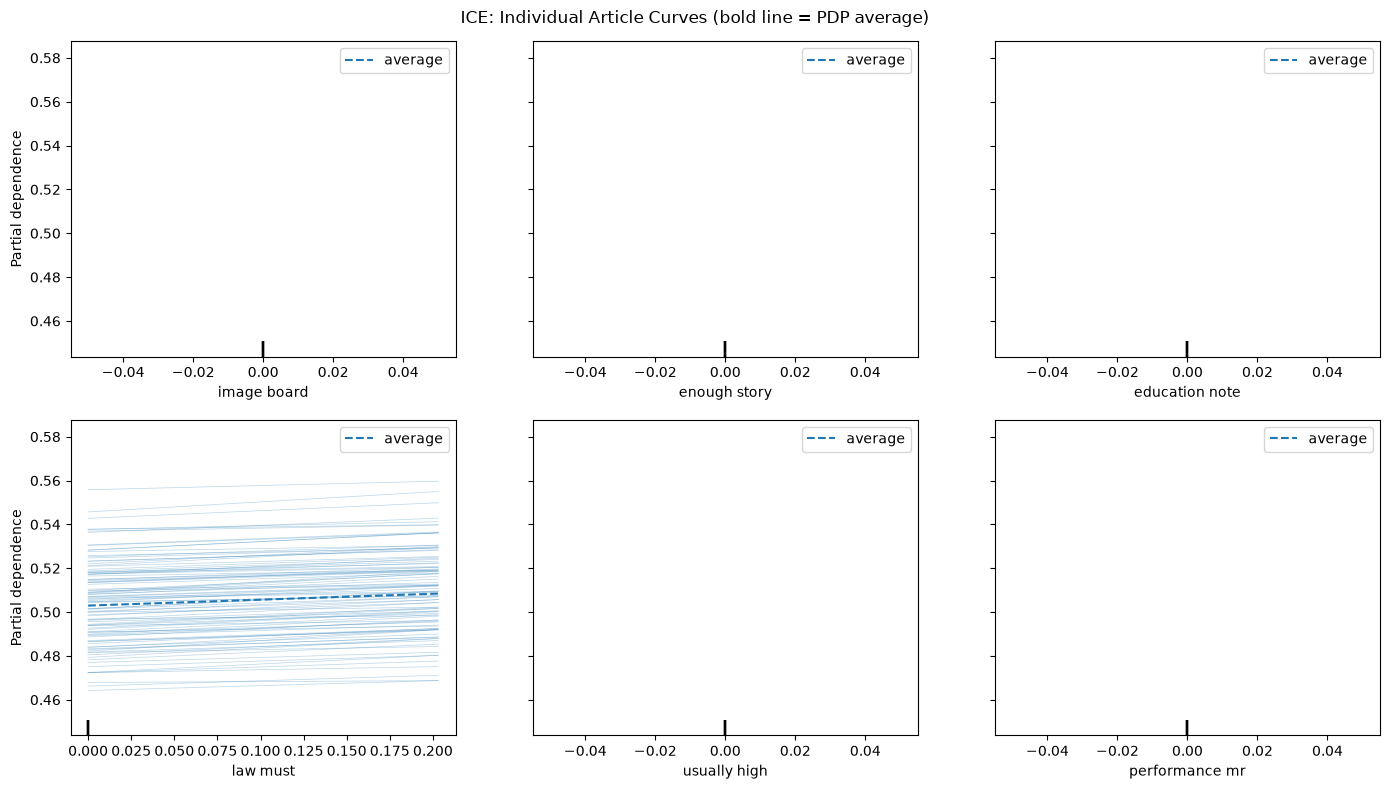

In [20]:
display = PartialDependenceDisplay.from_estimator(
    rf, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="both",
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
display.figure_.set_size_inches(14, 8)
display.figure_.suptitle("ICE: Individual Article Curves (bold line = PDP average)")
plt.tight_layout()
plt.show()

## 12. Individual Decisions (LIME and SHAP)

Explain why did the model make this particular prediction?

### 12.1 LIME: Word-Removal Sanity Checks

LIME removes words from one article and watches how the predicted probability changes. Three cases are inspected: a correctly caught fake article (TP), a missed fake article (FN), and a real article wrongly flagged (FP). Weights are for the **fake** class: positive = pushes toward fake.

In [21]:
explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    return rf.predict_proba(tfidf.transform(texts))

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = rf.predict_proba(X_test)[:, 1]

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

True Positive (fake, caught) | P(fake) = 0.590


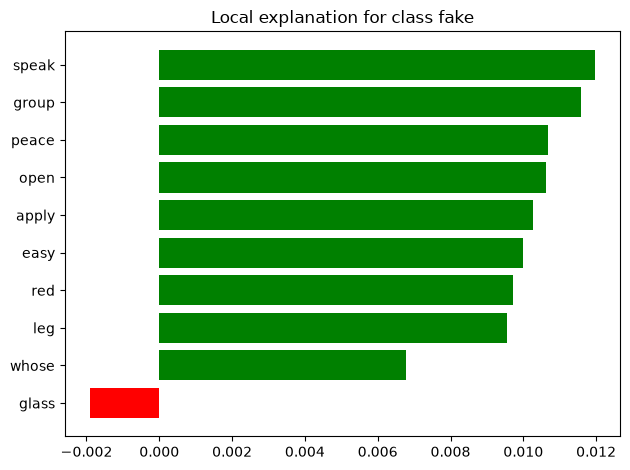

False Negative (fake, missed) | P(fake) = 0.442


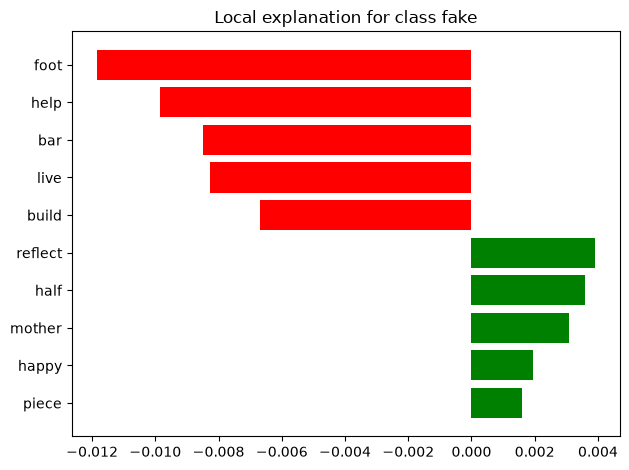

False Positive (real, flagged) | P(fake) = 0.588


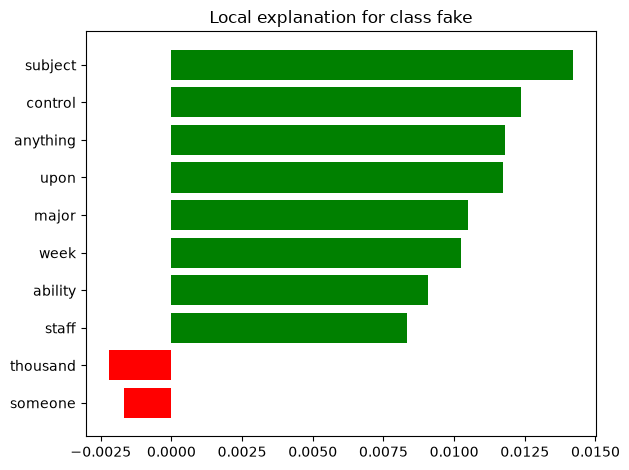

In [22]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=10, num_samples=1000, labels=(1,)
    )
    print(f"{name} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

### 12.2 SHAP Waterfall (one article)

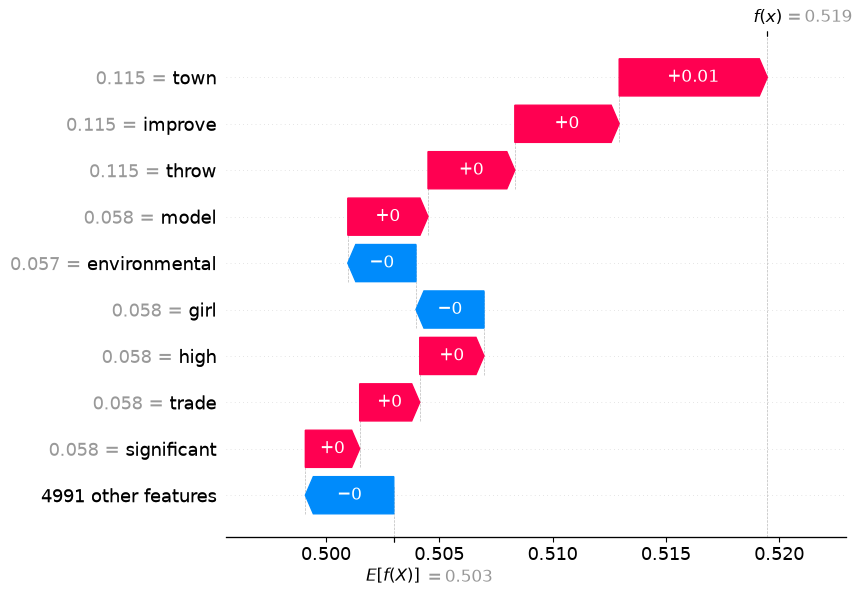

In [23]:
shap.plots.waterfall(
    shap.Explanation(
        values=sv_fake[0], base_values=base_value,
        data=X_shap[0], feature_names=list(feature_names)
    ),
    max_display=10
)